# HYROX 대회 기록 분석 : 회귀

**전반부(1~4구간) 기록으로 후반부(5~8구간) 소요 시간을 예측하는 회귀 모델을 고르고, 시즌 기준 시험 데이터로 성능을 비교하는 단계**

## 개요
- 목적: 전반부 기록으로 후반부 소요 시간(분)을 예측하는 회귀 모델 선택 및 성능 비교
- 데이터: 02에서 저장한 분석용 데이터 `clean` 59,886건 (학습 S4·S5, 시험 S6). 분석 범위는 open·pro 부문
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)
- 도구: VS Code, Claude

## 구성
1. 문제 정의와 분할
   - 작업: 전반 12열(입력)과 후반 소요 시간(예측 대상)을 정하고, 시즌으로 학습(S4·S5)과 시험(S6)을 분할
   - 도출: 입력 `X_train`·`X_test`, 예측 대상 `y_train`·`y_test`
2. 선형 관계 확인
   - 작업: 학습 데이터에서 입력 열별 상관계수와 산점도, 입력 열끼리의 상관계수 확인
   - 도출: 모델 후보를 정하는 관찰 근거
3. 모델 선택과 비교
   - 작업: 기준선 2개와 모델 3개를 시즌 2분할 검증으로 비교하고 검증 점수를 막대그래프로 확인해 모델을 고르고, 고른 모델을 시험 데이터로 평가
   - 도출: 선택 모델 `final`, 시험 점수
4. 오차 확인
   - 작업: 시험 예측의 오차 평균, 오차 절대값 중앙값, 후반 소요 시간 구간별 MAE 확인
   - 도출: 오차 `err`와 구간별 MAE

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

plt.rc("font", family="Malgun Gothic")  # 한글 표시 오류 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)  # 음수 부호(-) 표시 오류 방지

## 1. 문제 정의와 분할

**핵심:** 입력과 겹치지 않는 후반부 소요 시간을 예측 대상으로 정하고, 시즌으로 나누어 S4·S5로 학습, S6으로 시험

### 작업 내용
- 예측 대상(Y): 후반 소요 시간 = 5~8구간의 런·스테이션·록스존 시간 합 (분)
- 입력(X): 1~4구간의 런·스테이션·록스존 시간 12열
- 총 기록과 구간 합의 일치 확인 후, 입력과 예측 대상의 열이 겹치지 않도록 구간을 나눔
- 분할 기준: 시즌(`event_name` 앞 2글자)
- 분할 방식: S4·S5는 학습, S6은 시험
- 원본이 대회 단위로 묶여 있어(01) 시즌 단위로 분할
- `roxzone_8`: 02에서 전 기록이 0초로 확인되어 예측 대상에서 제외

### 확인 포인트
- 총 기록과 유형별 전체 열 합의 불일치 건수
- 입력 열과 예측 대상 열의 겹침 여부
- 학습·시험 기록 수

In [34]:
# notebooks/ 폴더 기준 상대 경로로 data/ 폴더 접근
clean = pd.read_csv("../data/hyrox_clean.csv")  # 02에서 저장한 분석용 데이터
clean["season"] = clean["event_name"].str.extract(r"^(S\d)")[0]  # 대회 이름 앞 2글자

print("clean.shape:", clean.shape)
print("시즌별 기록 수(건):", clean["season"].value_counts().sort_index().to_dict())

clean.shape: (59886, 68)
시즌별 기록 수(건): {'S4': 9997, 'S5': 26009, 'S6': 23880}


In [35]:
early_cols = [f"{k}_{i}_sec" for i in range(1, 5) for k in ["run", "work", "roxzone"]]
late_cols = (
    [f"run_{i}_sec" for i in range(5, 9)]
    + [f"work_{i}_sec" for i in range(5, 9)]
    + [f"roxzone_{i}_sec" for i in range(5, 8)]  # roxzone_8은 전 기록이 0초라 제외
)

total_diff = clean["run_time_sec"] + clean["work_time_sec"] + clean["roxzone_time_sec"] - clean["total_sec"]
print("입력 열 수:", len(early_cols), "/ 예측 대상 열 수:", len(late_cols))
print("총 기록과 세 유형 합의 불일치(건):", (total_diff != 0).sum())
print("입력·예측 대상에 겹치는 열:", set(early_cols) & set(late_cols))

입력 열 수: 12 / 예측 대상 열 수: 11
총 기록과 세 유형 합의 불일치(건): 0
입력·예측 대상에 겹치는 열: set()


In [36]:
X_all = clean[early_cols]  # 입력: 전반 12열
y_all = clean[late_cols].sum(axis=1) / 60  # 예측 대상: 후반 소요 시간(분)

is_train = clean["season"].isin(["S4", "S5"])  # 학습: S4·S5, 시험: 나머지(S6)
X_train, X_test = X_all[is_train], X_all[~is_train]
y_train, y_test = y_all[is_train], y_all[~is_train]

print("학습(S4·S5):", len(X_train), "건 / 시험(S6):", len(X_test), "건")

학습(S4·S5): 36006 건 / 시험(S6): 23880 건


### 결과
- 총 기록과 세 유형(런·스테이션·록스존) 합의 불일치 0건
- 입력 열과 예측 대상 열이 겹치지 않음
- 학습(S4·S5) 36,006건, 시험(S6) 23,880건

### 추정·한계
- 선수 식별 열이 없어 같은 선수의 기록이 학습과 시험 양쪽에 있는지, 있다면 시즌 사이 실력 변화가 점수에 준 영향은 구분 불가

### 한 줄 정리
- 입력 12열과 겹치지 않는 후반 11열의 합을 예측 대상으로 정하고, 시즌으로 나누어 학습 36,006건, 시험 23,880건으로 분할함

## 2. 선형 관계 확인

**핵심:** 학습 데이터(S4·S5)에서 입력 12열과 후반 소요 시간의 직선 관계, 입력 12열끼리의 상관을 확인

### 작업 내용
- 대상: 1절에서 나눈 학습 데이터 36,006건 (시험 데이터는 모델 선택에 쓰지 않음)
- 입력 12열 각각과 후반 소요 시간의 상관계수 계산
- 12열 각각의 산점도 작성 (학습 데이터 전체)
- 입력 12열끼리의 상관계수 계산

### 확인 포인트
- 입력 열별 상관계수
- 산점도의 점 분포 모양 (직선 여부)
- 입력 열끼리의 상관계수

In [37]:
corr = X_train.corrwith(y_train).round(2)  # 학습 데이터 기준, 입력 열별 상관계수
print("입력 열별 후반 소요 시간과의 상관계수:")
print(corr.sort_values(ascending=False).to_string())

입력 열별 후반 소요 시간과의 상관계수:
run_4_sec        0.78
run_3_sec        0.73
work_4_sec       0.72
run_2_sec        0.71
run_1_sec        0.54
work_3_sec       0.52
work_1_sec       0.51
roxzone_4_sec    0.43
roxzone_2_sec    0.43
roxzone_3_sec    0.41
work_2_sec       0.38
roxzone_1_sec    0.25


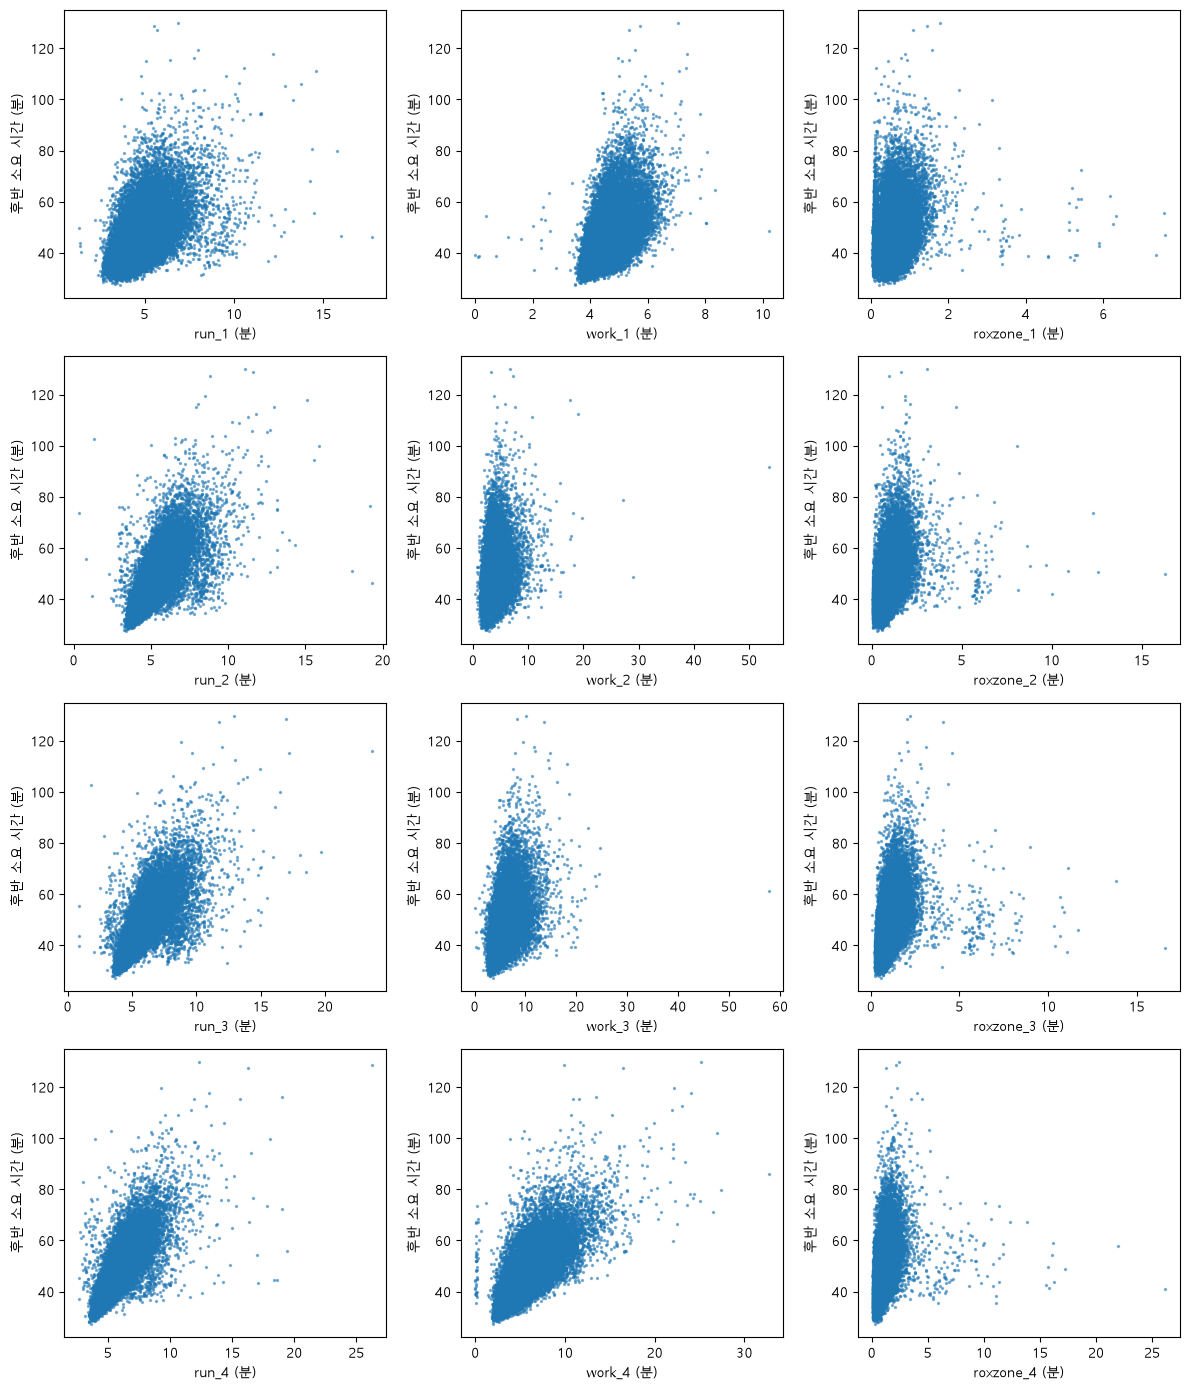

In [38]:
fig, axes = plt.subplots(4, 3, figsize=(12, 14))
for ax, col in zip(axes.ravel(), early_cols):
    ax.scatter(X_train[col] / 60, y_train, s=2, alpha=0.5)  # 전체 점, 투명도로 겹침 표시
    ax.set_xlabel(f"{col.replace('_sec', '')} (분)")
    ax.set_ylabel("후반 소요 시간 (분)")
plt.tight_layout()
plt.show()

In [39]:
corr_x = X_train.corr().round(2)  # 학습 데이터 기준, 입력 열끼리의 상관계수
corr_x.columns = corr_x.columns.str.replace("_sec", "")  # 출력 폭을 줄이기 위한 열 이름 단축
corr_x.index = corr_x.index.str.replace("_sec", "")
print("입력 열끼리의 상관계수:")
print(corr_x.to_string())

입력 열끼리의 상관계수:
           run_1  work_1  roxzone_1  run_2  work_2  roxzone_2  run_3  work_3  roxzone_3  run_4  work_4  roxzone_4
run_1       1.00    0.48       0.18   0.61    0.12       0.26   0.52    0.26       0.27   0.56    0.49       0.26
work_1      0.48    1.00       0.16   0.54    0.16       0.25   0.46    0.44       0.23   0.50    0.54       0.24
roxzone_1   0.18    0.16       1.00   0.21    0.03       0.24   0.19    0.03       0.23   0.19    0.23       0.09
run_2       0.61    0.54       0.21   1.00    0.20       0.28   0.77    0.36       0.30   0.80    0.58       0.31
work_2      0.12    0.16       0.03   0.20    1.00       0.18   0.25    0.56       0.21   0.23    0.18       0.12
roxzone_2   0.26    0.25       0.24   0.28    0.18       1.00   0.36    0.23       0.42   0.35    0.34       0.30
run_3       0.52    0.46       0.19   0.77    0.25       0.36   1.00    0.39       0.30   0.83    0.55       0.33
work_3      0.26    0.44       0.03   0.36    0.56       0.23   0.39    1.

In [40]:
pairs = corr_x.where(np.triu(np.ones(corr_x.shape, dtype=bool), k=1)).stack()  # 대각선 위쪽 66쌍만 추출
print("입력 열 쌍 상관계수 상위 5:")
print(pairs.sort_values(ascending=False).head(5).to_string())

입력 열 쌍 상관계수 상위 5:
run_3  run_4     0.83
run_2  run_4     0.80
       run_3     0.77
run_1  run_2     0.61
run_4  work_4    0.60


### 결과
- 입력 12열 모두 후반 소요 시간과의 상관계수가 양수 (0.25~0.78)
- 런 상관계수는 1구간에서 4구간으로 갈수록 커짐 (0.54, 0.71, 0.73, 0.78)
- 산점도에서 런 4개와 work_1·work_4는 점 덩어리가 오른쪽 위로 기울어진 모양
- 산점도에서 work_2·work_3와 록스존 4개는 점 덩어리가 세로로 선 모양이며, 오른쪽 멀리에 점이 드물게 있음
- 입력 열끼리의 상관계수가 가장 큰 3쌍은 모두 런 2·3·4구간끼리의 쌍 (0.77~0.83)
- 그다음으로 큰 입력 열 쌍의 상관계수는 0.61

**입력 열별 상관계수 (후반 소요 시간 기준)**

| 구간 | 런 | 스테이션 | 록스존 |
|---|---|---|---|
| 1 | 0.54 | 0.51 | 0.25 |
| 2 | 0.71 | 0.38 | 0.43 |
| 3 | 0.73 | 0.52 | 0.41 |
| 4 | 0.78 | 0.72 | 0.43 |

**입력 열끼리 상관계수가 가장 큰 3쌍**

| 입력 열 쌍 | 상관계수 |
|---|---|
| run_3, run_4 | 0.83 |
| run_2, run_4 | 0.80 |
| run_2, run_3 | 0.77 |

### 추정·한계
- 후반에 가까운 4구간의 상관이 큰 원인은 이 결과만으로 구분 불가
- 스테이션 2·3구간과 록스존의 상관이 작은 원인(값의 범위, 오른쪽 멀리 떨어진 점 등)은 구분 불가
- 입력 열 두 개씩의 상관만 보았으며, 여러 열이 함께 선형 종속에 가까운지는 확인하지 못함

### 한 줄 정리
- 입력 12열 모두 후반 소요 시간과 양의 상관(0.25~0.78)이며, 런 2·3·4구간끼리의 상관이 0.77~0.83으로 가장 큼

## 3. 모델 선택과 비교

**핵심:** 기준선 2개와 선형 회귀·릿지 회귀·랜덤 포레스트를 시즌 2분할 검증으로 비교해 모델을 고르고, 고른 모델을 S6 시험 데이터로 평가

### 작업 내용
- 기준선 2개
  - 학습 평균: 학습 데이터의 후반 소요 시간 평균을 그대로 예측
  - 전반 합 × 비율: 전반 합에 학습 데이터의 후반 ÷ 전반 중앙값을 곱함
- 모델 3개: 선형 회귀, 릿지 회귀, 랜덤 포레스트
- 모델 선정 근거
  - 선형 회귀: 비교의 기준이 되는 가장 단순한 선형 모델
  - 릿지 회귀: 공식 순서도(scikit-learn 1.9)의 선형 모델이며, 2절에서 런 2·3·4구간끼리 입력 상관이 0.77~0.83
  - 랜덤 포레스트: 공식 순서도의 앙상블 회귀(Ensemble Regressors) 계열
- 설정값: scikit-learn 공식 문서의 기본값 사용
  - 릿지 회귀 `alpha=1.0`
  - 랜덤 포레스트 `n_estimators=100`, `min_samples_leaf=1`
- 랜덤 포레스트 `random_state=42` 고정 (결과 재현용)
- 점수 방식: 시즌 2분할 검증, S4로 학습해 S5로 검증하고 S5로 학습해 S4로 검증
- 지표: MAE(분)와 R²
- 검증 점수 확인: 기준선·모델별 검증 점수를 MAE와 R² 막대그래프로 작성
- 모델 선택: 검증 점수(MAE, R²) 기준
- 최종 평가: 고른 모델을 학습 데이터(S4·S5) 전체로 다시 학습해 S6 시험 데이터로 점수 확인 (S6은 모델 선택에 쓰지 않음)

### 확인 포인트
- 기준선·모델별 검증 점수 (MAE, R²)
- 기준선 대비 모델의 점수 차이
- 모델 간 점수 차이
- 검증 방향(S4→S5, S5→S4)별 점수 차이
- 선택한 모델의 시험(S6) 점수

In [41]:
folds = [("S4", "S5"), ("S5", "S4")]  # (학습 시즌, 검증 시즌)
season = clean["season"]

def make_models():
    """모델 3개 (scikit-learn 공식 문서의 기본값, random_state는 재현용)"""
    return {
        "선형 회귀": LinearRegression(),
        "릿지 회귀": Ridge(alpha=1.0),
        "랜덤 포레스트": RandomForestRegressor(n_estimators=100, min_samples_leaf=1, random_state=42),
    }

rows = {}
for tr, va in folds:
    X_tr, y_tr = X_all[season == tr], y_all[season == tr]
    X_va, y_va = X_all[season == va], y_all[season == va]
    ratio = (y_tr * 60 / X_tr.sum(axis=1)).median()  # 후반 ÷ 전반 중앙값, 학습 시즌만 사용
    preds = {
        "기준선: 학습 평균": np.full(len(y_va), y_tr.mean()),
        "기준선: 전반 합 × 비율": X_va.sum(axis=1) * ratio / 60,
    }
    for name, model in make_models().items():
        preds[name] = model.fit(X_tr, y_tr).predict(X_va)
    for name, p in preds.items():
        rows.setdefault(name, {})[f"{tr}→{va} MAE(분)"] = mean_absolute_error(y_va, p)
        rows[name][f"{tr}→{va} R²"] = r2_score(y_va, p)

val_result = pd.DataFrame(rows).T.round(2)
print(val_result.to_string())

                S4→S5 MAE(분)  S4→S5 R²  S5→S4 MAE(분)  S5→S4 R²
기준선: 학습 평균              7.06     -0.00          6.64     -0.00
기준선: 전반 합 × 비율          3.15      0.78          3.56      0.68
선형 회귀                   3.10      0.79          3.32      0.70
릿지 회귀                   3.10      0.79          3.32      0.70
랜덤 포레스트                 3.04      0.79          3.19      0.73


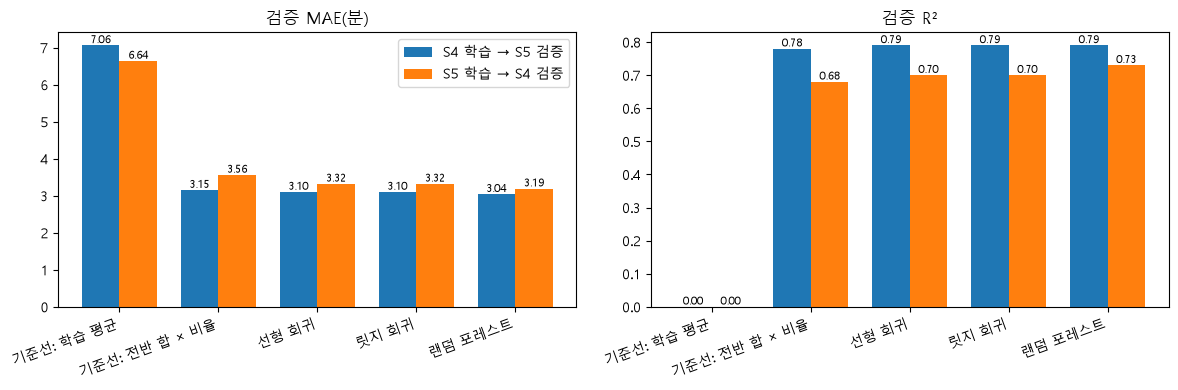

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(val_result))
w = 0.38  # 막대 너비

for ax, metric in zip(axes, ["MAE(분)", "R²"]):
    b1 = ax.bar(x - w / 2, val_result[f"S4→S5 {metric}"], w, label="S4 학습 → S5 검증")
    b2 = ax.bar(x + w / 2, val_result[f"S5→S4 {metric}"], w, label="S5 학습 → S4 검증")
    ax.bar_label(b1, fmt="%.2f", fontsize=8)  # 막대 차이가 작아 값을 표시
    ax.bar_label(b2, fmt="%.2f", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(val_result.index, rotation=20, ha="right")
    ax.set_title(f"검증 {metric}")

axes[0].legend()
plt.tight_layout()
plt.show()

In [43]:
final = make_models()["랜덤 포레스트"].fit(X_train, y_train)  # 학습 데이터(S4·S5) 전체로 다시 학습
ratio = (y_train * 60 / X_train.sum(axis=1)).median()  # 후반 ÷ 전반 중앙값, 학습 데이터만 사용

test_preds = {
    "기준선: 학습 평균": np.full(len(y_test), y_train.mean()),
    "기준선: 전반 합 × 비율": X_test.sum(axis=1) * ratio / 60,
    "랜덤 포레스트": final.predict(X_test),
}
test_result = pd.DataFrame({
    name: {"MAE(분)": mean_absolute_error(y_test, p), "R²": r2_score(y_test, p)}
    for name, p in test_preds.items()
}).T.round(2)
print("시험(S6) 점수:")
print(test_result.to_string())

시험(S6) 점수:
                MAE(분)    R²
기준선: 학습 평균        7.16 -0.01
기준선: 전반 합 × 비율    3.36  0.77
랜덤 포레스트           2.99  0.80


### 결과
- 검증 점수(S4로 학습해 S5로 검증 / S5로 학습해 S4로 검증)에서 랜덤 포레스트가 두 방향 모두 MAE가 가장 작음
- 선형 회귀와 릿지 회귀의 검증 점수가 소수점 2자리까지 같음
- 랜덤 포레스트와 선형 회귀의 MAE 차이는 S4→S5에서 0.06분, S5→S4에서 0.13분
- 학습 평균 기준선은 검증 MAE가 7.06분, 6.64분으로 나머지 4개(3.04~3.56분)보다 높고, R²는 -0.00
- 학습 평균 기준선을 뺀 4개 모두 S5→S4의 MAE가 S4→S5보다 크고(0.15~0.41분), R²는 0.06~0.10 낮음
- 랜덤 포레스트를 학습 데이터(S4·S5) 전체로 다시 학습해 시험(S6)에서 MAE 2.99분, R² 0.80
- 시험(S6)에서 랜덤 포레스트의 MAE는 학습 평균 기준선보다 4.17분, 전반 합 × 비율 기준선보다 0.37분 낮음

**검증 점수 (시즌 2분할)**

| 모델 | S4→S5 MAE (분) | S4→S5 R² | S5→S4 MAE (분) | S5→S4 R² |
|---|---|---|---|---|
| 기준선: 학습 평균 | 7.06 | -0.00 | 6.64 | -0.00 |
| 기준선: 전반 합 × 비율 | 3.15 | 0.78 | 3.56 | 0.68 |
| 선형 회귀 | 3.10 | 0.79 | 3.32 | 0.70 |
| 릿지 회귀 | 3.10 | 0.79 | 3.32 | 0.70 |
| 랜덤 포레스트 | 3.04 | 0.79 | 3.19 | 0.73 |

**시험(S6) 점수**

| 모델 | MAE (분) | R² |
|---|---|---|
| 기준선: 학습 평균 | 7.16 | -0.01 |
| 기준선: 전반 합 × 비율 | 3.36 | 0.77 |
| 랜덤 포레스트 | 2.99 | 0.80 |

### 추정·한계
- 랜덤 포레스트와 선형 회귀의 MAE 차이가 작고 검증이 2번뿐이라, 이 차이가 의미 있는 크기인지는 구분 불가
- 릿지 회귀와 선형 회귀의 검증 점수가 같은 원인은 구분 불가
- 설정값은 공식 문서의 기본값이며, 다른 설정값에서 점수가 어떻게 달라지는지는 확인하지 않음
- S5→S4의 점수가 S4→S5보다 낮은 원인(학습 기록 수 9,997건과 26,009건의 차이, 시즌 간 분포 차이 등)은 구분 불가

### 한 줄 정리
- 시즌 2분할 검증에서 MAE가 가장 작은 랜덤 포레스트를 택했고, 시험(S6)에서 MAE 2.99분(R² 0.80)으로 전반 합 × 비율 기준선(3.36분)보다 0.37분 낮음

## 4. 오차 확인

**핵심:** 3절에서 고른 랜덤 포레스트의 시험(S6) 예측 오차를 오차 평균·오차 절대값 중앙값과 후반 소요 시간 구간별 MAE로 확인

### 작업 내용
- 대상: 3절에서 학습 데이터(S4·S5) 전체로 다시 학습한 랜덤 포레스트의 시험(S6) 예측
- 오차 = 예측 - 실제 (양수이면 예측이 실제보다 큼)
- 오차 평균: 오차의 치우침 방향 확인
- 오차 절대값 중앙값: 전형적인 오차 크기 확인
- 구간별 MAE: 실제 후반 소요 시간 순서로 기록 수가 같도록 4구간으로 나누어 구간별 MAE 계산 후 막대그래프로 작성 (구간 수 4는 근거 없이 정한 값)

### 확인 포인트
- 오차 평균
- 오차 절대값 중앙값
- 후반 소요 시간 구간별 MAE

In [44]:
err = test_preds["랜덤 포레스트"] - y_test  # 오차 = 예측 - 실제 (분)
print("오차(분) 평균:", round(err.mean(), 2))
print("오차 절대값(분) 중앙값:", round(err.abs().median(), 2))

오차(분) 평균: -0.13
오차 절대값(분) 중앙값: 2.14


In [45]:
bins = pd.qcut(y_test, 4, labels=["하위 25%", "25~50%", "50~75%", "상위 25%"])  # 실제 후반 소요 시간 순서로 4등분
print("후반 소요 시간 구간별 MAE(분):")
print(err.abs().groupby(bins, observed=True).mean().round(2).to_string())

후반 소요 시간 구간별 MAE(분):
하위 25%    1.94
25~50%    2.23
50~75%    2.77
상위 25%    5.01


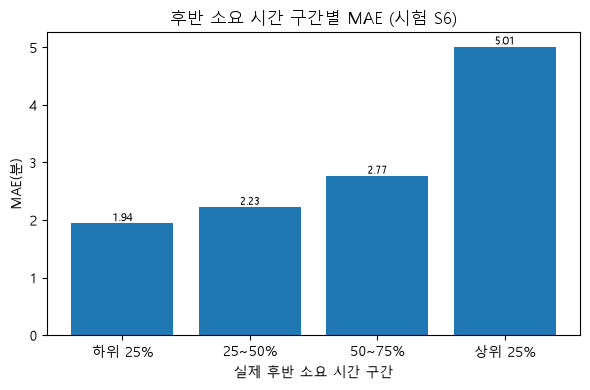

In [46]:
bin_mae = err.abs().groupby(bins, observed=True).mean()  # 구간별 MAE

fig, ax = plt.subplots(figsize=(6, 4))
b = ax.bar(bin_mae.index.astype(str), bin_mae.values)
ax.bar_label(b, fmt="%.2f", fontsize=8)
ax.set_xlabel("실제 후반 소요 시간 구간")
ax.set_ylabel("MAE(분)")
ax.set_title("후반 소요 시간 구간별 MAE (시험 S6)")
plt.tight_layout()
plt.show()

### 결과
- 오차(예측 - 실제) 평균 -0.13분
- 오차 절대값 중앙값 2.14분이며, 3절의 MAE 2.99분보다 작음
- 구간별 MAE는 후반 소요 시간이 긴 구간일수록 큼

**후반 소요 시간 구간별 MAE**

| 구간 | MAE (분) |
|---|---|
| 하위 25% | 1.94 |
| 25~50% | 2.23 |
| 50~75% | 2.77 |
| 상위 25% | 5.01 |

### 추정·한계
- 후반 소요 시간이 긴 기록에서 MAE가 큰 원인(모델의 약점, 구간을 실제 값으로 나눈 방식 등)은 구분 불가

### 한 줄 정리
- 시험(S6)에서 랜덤 포레스트의 오차 평균은 -0.13분이고, 후반 소요 시간이 긴 상위 25% 구간의 MAE가 5.01분으로 가장 큼